# HD 137010-b: Data Exploration

Bayesian inference of the orbital properties of the single-transit
Earth-sized exoplanet candidate HD 137010 b.

Data: K2 Campaign 15 photometry from Venner et al. (2026)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import ascii
import requests


In [7]:

data = np.loadtxt(
    "../data/apjladf06ft3_mrt.txt",
    skiprows=15
)

time = data[:, 0]
flux_normalized = data[:, 1]
flux_detrended = data[:, 2]

print(data)

[[3.1578752e+03 9.9945683e-01 1.0000828e+00]
 [3.1578956e+03 9.9943504e-01 1.0000273e+00]
 [3.1579160e+03 9.9941655e-01 9.9997813e-01]
 ...
 [3.2443630e+03 9.9970085e-01 9.9998146e-01]
 [3.2443835e+03 9.9971981e-01 1.0000025e+00]
 [3.2444243e+03 9.9971669e-01 1.0000050e+00]]


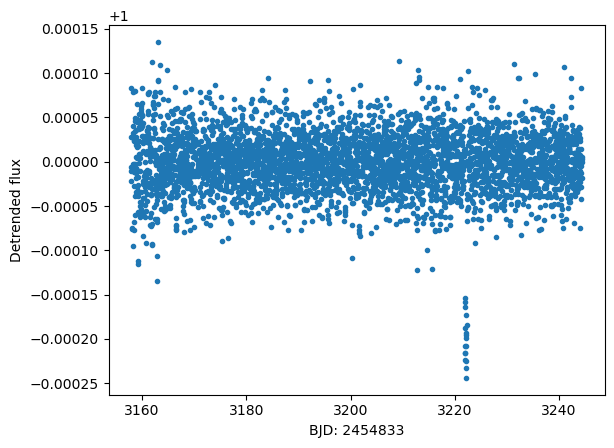

In [8]:
plt.plot(time, flux_detrended, ".")
plt.xlabel("BJD: 2454833")
plt.ylabel("Detrended flux")
plt.show()



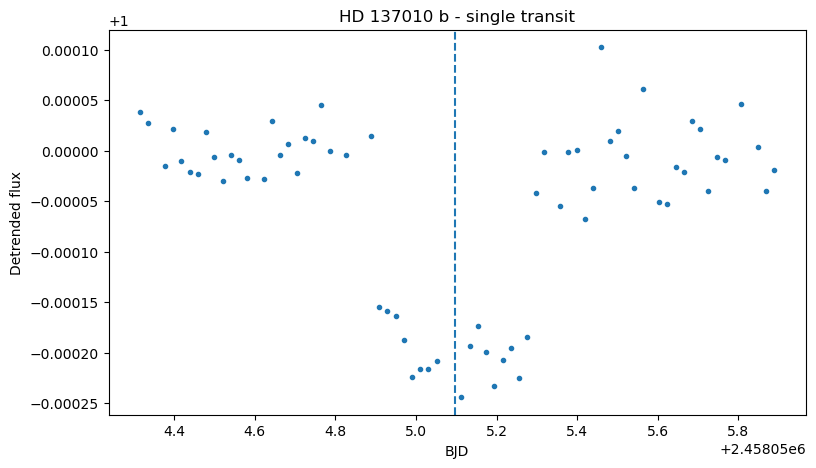

In [9]:
t = data[:, 0] + 2454833
flux = data[:, 2]

t0 = 2458055.0969

mask = np.abs(t - t0) < 0.8

t_transit = t[mask]
flux_transit = flux[mask]

plt.figure(figsize=(9, 5))
plt.plot(t_transit, flux_transit, ".")
plt.axvline(t0, linestyle="--")

plt.xlabel("BJD")
plt.ylabel("Detrended flux")
plt.title("HD 137010 b - single transit")
plt.show()

In [10]:
import batman

In [11]:
params = batman.TransitParams()

params.t0 = t0
params.per = 355.0
params.rp = 0.01368
params.a = 270.0

params.inc = 90.0       # first try: b = 0
params.ecc = 0.0
params.w = 90.0

params.u = [0.56, 0.10]
params.limb_dark = "quadratic"

In [13]:
model = batman.TransitModel(
    params,
    t_transit,
    supersample_factor=10,
    exp_time=29.4 / (24 * 60)
)

model_flux = model.light_curve(params)

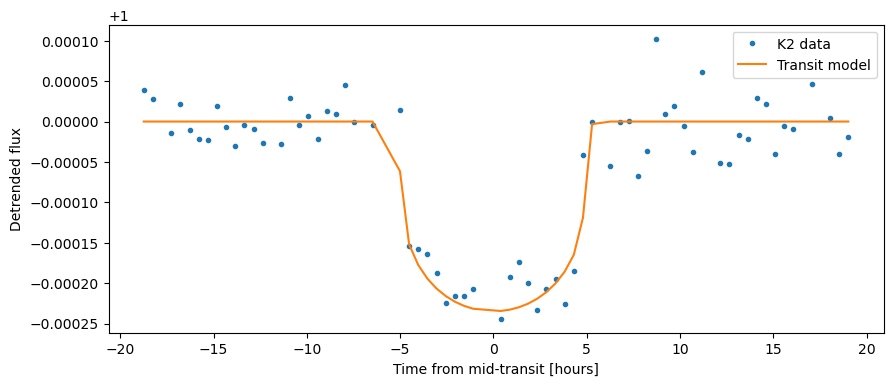

In [17]:
plt.figure(figsize=(10, 4))

plt.plot(
    (t_transit - t0) * 24,
    flux_transit,
    ".",
    label="K2 data"
)

plt.plot(
    (t_transit - t0) * 24,
    model_flux,
    label="Transit model"
)

plt.xlabel("Time from mid-transit [hours]")
plt.ylabel("Detrended flux")
plt.legend()
plt.show()

In [18]:
def transit_model(time, period, rp, b, t0, rho_star,
                  u1=0.56, u2=0.10):

    a_Rstar = a_over_rstar(period, rho_star)

    # for circular orbit:
    inclination = np.degrees(
        np.arccos(b / a_Rstar)
    )

    params = batman.TransitParams()

    params.t0 = t0
    params.per = period
    params.rp = rp
    params.a = a_Rstar
    params.inc = inclination

    params.ecc = 0.0
    params.w = 90.0

    params.u = [u1, u2]
    params.limb_dark = "quadratic"

    model = batman.TransitModel(
        params,
        time,
        supersample_factor=10,
        exp_time=29.4 / (24 * 60)
    )

    return model.light_curve(params)

In [21]:
test_model = transit_model(
    t_transit,
    period=355,
    rp=0.01368,
    b=0,
    t0=t0,
    rho_star=2.90
)

NameError: name 'a_over_rstar' is not defined